In [17]:
# Install required libraries
!pip install pandas scikit-learn seaborn matplotlib imbalanced-learn

# Import libraries
import pandas as pd
import numpy as np
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
import seaborn as sns
import matplotlib.pyplot as plt

# Random seed for reproducibility
np.random.seed(42)


In [18]:
# Load dataset (replace with your actual path)
dataset_path = "/content/AsjadComments.csv"
df = pd.read_csv(dataset_path)

# Preview
print("Dataset Preview:")
print(df.head())
print("\nDataset Info:")
print(df.info())
print("\nLabel Distribution:")
print(df['label'].value_counts())


Dataset Preview:
                                                text        label
0  Ya jo log idher galiyan de rha ha unko chahia ...  non-abusive
1   What do you guys think now after he apologized ?  non-abusive
2  Junaid Bhai woh Islamabad Airport auction hoga...  non-abusive
3                    So disappointed with your video  non-abusive
4  Lol. I&#39;m from interior sindh and even my c...      abusive

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10634 entries, 0 to 10633
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    10634 non-null  object
 1   label   10634 non-null  object
dtypes: object(2)
memory usage: 166.3+ KB
None

Label Distribution:
label
non-abusive    9688
abusive         946
Name: count, dtype: int64


In [19]:
print("Missing Values:\n", df.isnull().sum())
print("Duplicate Rows:", df.duplicated().sum())


Missing Values:
 text     0
label    0
dtype: int64
Duplicate Rows: 255


In [20]:
# Drop NaN and duplicates
df = df.dropna().drop_duplicates()

print("After Cleaning:")
print("Rows:", df.shape[0])
print("Missing Values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())


After Cleaning:
Rows: 10379
Missing Values: 0
Duplicates: 0


In [21]:
# Remove outliers by text length (too short/too long)
df['len'] = df['text'].str.split().apply(len)
print(df['len'].describe())
df = df[(df['len'] >= 2) & (df['len'] <= 200)].copy()
df.drop(columns=['len'], inplace=True)
print("After outlier removal, rows:", df.shape[0])


count    10379.000000
mean        19.082089
std         22.328363
min          1.000000
25%          7.000000
50%         13.000000
75%         23.000000
max        463.000000
Name: len, dtype: float64
After outlier removal, rows: 10314


In [22]:
df.head()

,text,label
0,Ya jo log idher galiyan de rha ha unko chahia ...,non-abusive
1,What do you guys think now after he apologized ?,non-abusive
2,Junaid Bhai woh Islamabad Airport auction hoga...,non-abusive
3,So disappointed with your video,non-abusive
4,Lol. I&#39;m from interior sindh and even my c...,abusive


In [23]:
stop_words = {'hai','aur','ke','ka','ki','ko','mein','se','bhi','ye','wo','nahi'}

def normalize_roman_urdu(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)   # remove URLs
    text = re.sub(r'[^\w\s]', '', text)                   # remove special chars
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)            # reduce repeats

    # common replacements
    replacements = {
        'hy':'hai','hye':'hai','hey':'hai',
        'nhi':'nahi','nai':'nahi',
        'kr':'kar','krna':'karna','krtay':'karte'
    }
    for k,v in replacements.items():
        text = re.sub(r'\b'+re.escape(k)+r'\b', v, text)

    tokens = [t for t in text.split() if t not in stop_words]
    return " ".join(tokens)

df['text'] = df['text'].astype(str).apply(normalize_roman_urdu)

print("Preprocessed Preview:")
print(df.head())


Preprocessed Preview:
                                                text        label
0  ya jo log idher galiyan de rha ha unko chahia ...  non-abusive
1     what do you guys think now after he apologized  non-abusive
2  junaid bhai woh islamabad airport auction hoga...  non-abusive
3                    so disappointed with your video  non-abusive
4  lol i39m from interior sindh and even my city ...      abusive


In [24]:
tfidf = TfidfVectorizer(ngram_range=(1,3), max_features=10000)
X = tfidf.fit_transform(df['text'])
y = df['label']

print("Feature Matrix Shape:", X.shape)


Feature Matrix Shape: (10314, 10000)


In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Training Set Size:", X_train.shape)
print("Testing Set Size:", X_test.shape)
print("Label distribution in Train:\n", y_train.value_counts(normalize=True))
print("Label distribution in Test:\n", y_test.value_counts(normalize=True))


Training Set Size: (7735, 10000)
Testing Set Size: (2579, 10000)
Label distribution in Train:
 label
non-abusive    0.9117
abusive        0.0883
Name: proportion, dtype: float64
Label distribution in Test:
 label
non-abusive    0.911594
abusive        0.088406
Name: proportion, dtype: float64


In [26]:
sm = SMOTE(random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train, y_train)

print("Before SMOTE:", y_train.value_counts())
print("After SMOTE:", y_train_res.value_counts())


Before SMOTE: label
non-abusive    7052
abusive         683
Name: count, dtype: int64
After SMOTE: label
non-abusive    7052
abusive        7052
Name: count, dtype: int64


In [27]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42, n_estimators=100)
}


In [28]:
for name, model in models.items():
    model.fit(X_train_res, y_train_res)
    print(f"{name} trained successfully.")


Logistic Regression trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.


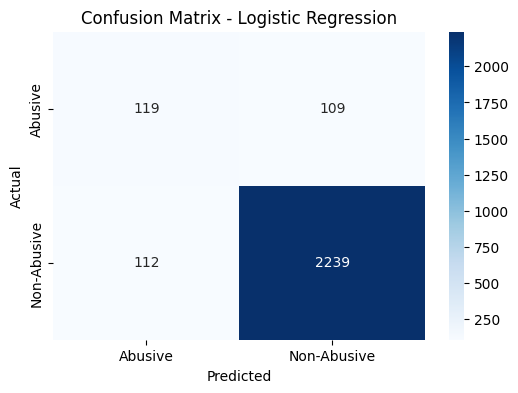

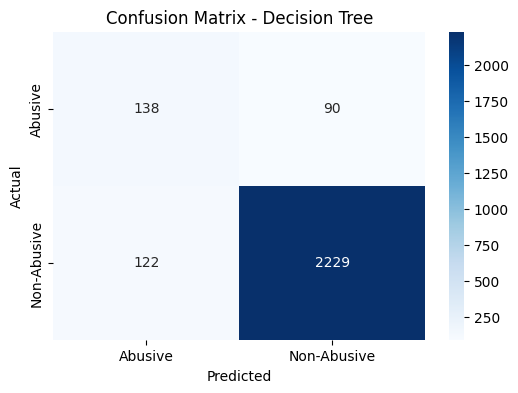

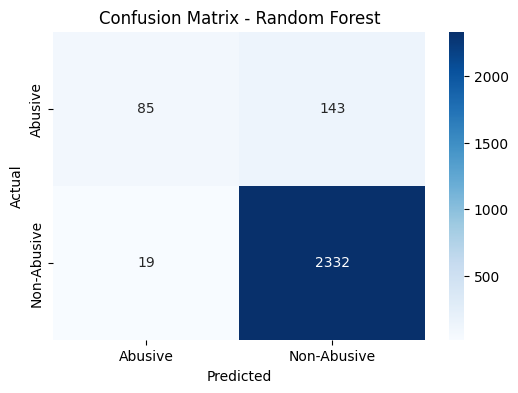

In [29]:
for name, model in models.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=['abusive','non-abusive'])

    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Abusive','Non-Abusive'],
                yticklabels=['Abusive','Non-Abusive'])
    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()


In [30]:
results = {}
for name, model in models.items():
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    print(f"\n{name} Performance:")
    print(f"Accuracy: {acc:.4f}")
    print(classification_report(y_test, y_pred, target_names=['abusive','non-abusive'], digits=4))

print("\nAccuracy Comparison:")
for k,v in results.items():
    print(f"{k}: {v:.4f}")

best_model = max(results, key=results.get)
print(f"\nBest Model: {best_model} with accuracy {results[best_model]:.4f}")



Logistic Regression Performance:
Accuracy: 0.9143
              precision    recall  f1-score   support

     abusive     0.5152    0.5219    0.5185       228
 non-abusive     0.9536    0.9524    0.9530      2351

    accuracy                         0.9143      2579
   macro avg     0.7344    0.7371    0.7357      2579
weighted avg     0.9148    0.9143    0.9146      2579


Decision Tree Performance:
Accuracy: 0.9178
              precision    recall  f1-score   support

     abusive     0.5308    0.6053    0.5656       228
 non-abusive     0.9612    0.9481    0.9546      2351

    accuracy                         0.9178      2579
   macro avg     0.7460    0.7767    0.7601      2579
weighted avg     0.9231    0.9178    0.9202      2579


Random Forest Performance:
Accuracy: 0.9372
              precision    recall  f1-score   support

     abusive     0.8173    0.3728    0.5120       228
 non-abusive     0.9422    0.9919    0.9664      2351

    accuracy                         0.93

/tmp/ipython-input-631706834.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x='Model', y='Accuracy', palette='viridis')


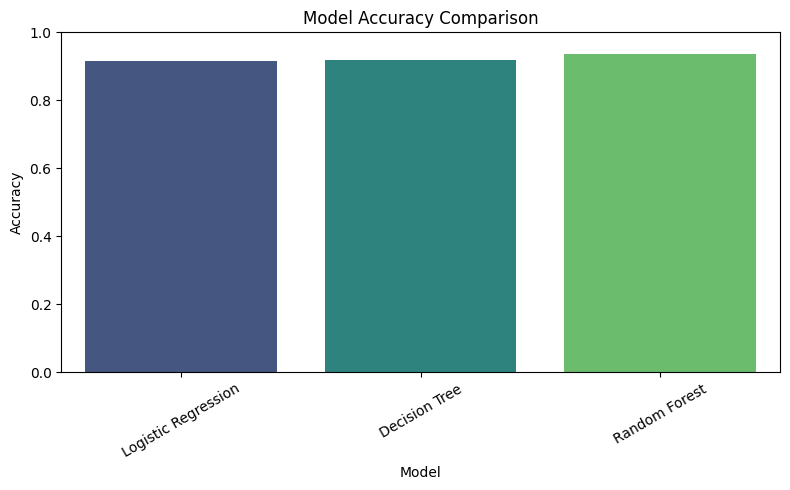

In [31]:
results_df = pd.DataFrame(list(results.items()), columns=['Model','Accuracy'])

plt.figure(figsize=(8,5))
sns.barplot(data=results_df, x='Model', y='Accuracy', palette='viridis')
plt.title("Model Accuracy Comparison")
plt.ylim(0,1)
plt.ylabel("Accuracy")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [32]:
import joblib

for name, model in models.items():
    filename = name.lower().replace(" ","_") + ".joblib"
    joblib.dump(model, filename)
    print(f"Saved {name} as {filename}")

joblib.dump(tfidf, "tfidf_vectorizer.joblib")
print("Saved TF-IDF vectorizer.")


Saved Logistic Regression as logistic_regression.joblib
Saved Decision Tree as decision_tree.joblib
Saved Random Forest as random_forest.joblib
Saved TF-IDF vectorizer.
